# Quantum Sports Scheduler: Classical Python vs. Quantum QAOA

**IBM Qiskit Fall Fest 2026 · Miami Dade College Hackathon**
Repository: <https://github.com/bassette143/quantum-sports-scheduler>

**Research question.** Can a quantum optimization algorithm (QAOA) help schedule a
sports tournament, and how does it compare with ordinary Python code?

**Short answer from our measurements.** Classical Python built an optimal schedule
for our wrestling tournament. On a smaller 14-variable decision, QAOA on a
simulator found valid answers more often than random guessing, but less reliably
and much more slowly than classical code. We also ran the same QAOA circuit **on a
real IBM quantum processor (ibm_fez)**. It still beat random guessing (13.2% vs. 7.9%
valid), but noise cut its success rate well below the simulator's 23.5%. **We did
not show a quantum advantage, and we do not claim one.**

### How to read this notebook
* Every number comes either from code that runs in this notebook or from our saved
  result files in `results/`. Nothing is typed in by hand.
* This notebook **does not change** any saved result. The last cell checks that.
* Cells marked **"Saved result"** read a file. Cells marked **"Live check"**
  run our code again now.
* **Simulator** means a regular computer imitating a perfect quantum computer.
  **Hardware** means a real IBM quantum processor. **Prediction** means a noise model
  run on a regular computer. We label each one clearly.

In [1]:
# Setup: load libraries and fingerprint the saved results so we can prove
# at the end that this notebook did not modify them.
import hashlib, json, platform, time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import qiskit, qiskit_aer
from IPython.display import Image, display, Markdown

PROJECT = Path.cwd()
assert (PROJECT / "wrestling").is_dir(), "Open this notebook from the project folder."
RESULTS = PROJECT / "results"

def load(name):
    return json.loads((RESULTS / name).read_text(encoding="utf-8"))

def fingerprint():
    return {p.name: hashlib.sha256(p.read_bytes()).hexdigest()
            for p in sorted(RESULTS.iterdir()) if p.is_file()}

BEFORE = fingerprint()
print(f"Python {platform.python_version()} | Qiskit {qiskit.__version__} | Qiskit Aer {qiskit_aer.__version__}")
print(f"{len(BEFORE)} saved result files fingerprinted in results/")

Python 3.11.9 | Qiskit 2.6.1 | Qiskit Aer 0.18.2
17 saved result files fingerprinted in results/


## 1. The sports scheduling problem

Wrestling tournaments run many weight classes at the same time on a few mats.
An organizer has to:

* run every match **exactly once**,
* respect **bracket order** (a semifinal can't start before both quarterfinals finish),
* give each wrestler **rest** between bouts,
* never put two matches on the **same mat at the same time**,
* and finish the whole event as **early as possible**.

The number of possible schedules grows extremely fast as more matches are added.
That makes scheduling a classic **optimization problem**, the kind of problem
quantum algorithms such as QAOA are being studied for.

We built a **fictional** tournament: 12 schools, 14 weight classes and 6 mats,
using single-elimination championship brackets. The rules are simplified: no
consolation brackets and no real match lengths.

In [2]:
# Live check: generate the fictional tournament (fixed seed 42, same as our research runs)
from wrestling.rosters import generate_rosters, tournament_statistics
from wrestling.brackets import generate_all_brackets

rosters = generate_rosters(42)
stats = tournament_statistics(rosters)
bracket_data = generate_all_brackets(42)

print("Schools:                 ", stats["total_schools"])
print("Weight classes:          ", len(stats["per_weight"]))
print("Wrestlers entered:       ", stats["total_wrestlers"])
print("First-round byes:        ", stats["total_byes"])
print("Matches to schedule:     ", stats["total_matches"])

saved = load("wrestling_brackets.json")["summary"]
print("\nSaved result agrees:", saved["total_wrestlers"] == stats["total_wrestlers"]
      and saved["total_byes"] == stats["total_byes"]
      and saved["total_projected_contested_matches"] == stats["total_matches"])

Schools:                  12
Weight classes:           14
Wrestlers entered:        132
First-round byes:         60
Matches to schedule:      118

Saved result agrees: True


## 2. How our classical algorithm solves the problem

We used **greedy list scheduling**, a simple and fast classical method. It goes
through time slots in order and places each match that is ready (its earlier
rounds are done and its wrestlers have rested) on a free mat.

Then a **separate, independent validator** checks the finished schedule against
every rule. We don't trust any solver, classical or quantum, until the validator
agrees.

**How good is the schedule?** 118 matches on 6 mats need at least
⌈118 ÷ 6⌉ = **20** time slots. No method can do better than this *lower bound*.

In [3]:
# Live check: build the full 118-match schedule and validate it independently
from wrestling.mat_schedule import schedule_matches, schedule_statistics, N_MATS, REST_SLOTS
from wrestling.mat_validator import validate_mat_schedule

t0 = time.perf_counter()
assignments = schedule_matches(bracket_data, N_MATS, REST_SLOTS)
elapsed = time.perf_counter() - t0

check = validate_mat_schedule(bracket_data, assignments, N_MATS, REST_SLOTS)
s = schedule_statistics(bracket_data, assignments, N_MATS, REST_SLOTS)
print(f"Matches scheduled:      {s['n_matches_scheduled']}")
print(f"Time slots used:        {s['makespan_slots']}")
print(f"Lower bound:            {s['theoretical_lower_bound_slots']}")
print(f"Mat utilization:        {s['mat_utilization_percent']}%")
print(f"Independent validator:  {'VALID' if check.is_valid else 'INVALID'}")
print(f"Time to schedule (this run): {elapsed*1000:.1f} ms")

saved = load("wrestling_mat_schedule.json")
print("\nSaved result agrees:", saved["statistics"]["makespan_slots"] == s["makespan_slots"]
      and saved["is_valid"] == check.is_valid)

Matches scheduled:      118
Time slots used:        20
Lower bound:            20
Mat utilization:        98.3%
Independent validator:  VALID
Time to schedule (this run): 0.6 ms

Saved result agrees: True


In [4]:
# Show the first three time slots of the schedule
by_slot = {}
for mid, a in assignments.items():
    by_slot.setdefault(a["slot"], []).append((a["mat"], mid))
for slot in (1, 2, 3):
    row = "  ".join(f"Mat {m}: {mid}" for m, mid in sorted(by_slot[slot]))
    print(f"Slot {slot}: {row}")
print("\nMatch ID format: W<weight>-R<round>-S<bracket position>")

Slot 1: Mat 1: W106-R1-S7  Mat 2: W106-R1-S8  Mat 3: W113-R1-S6  Mat 4: W113-R1-S7  Mat 5: W113-R1-S8  Mat 6: W120-R1-S2
Slot 2: Mat 1: W120-R1-S3  Mat 2: W120-R1-S4  Mat 3: W126-R1-S6  Mat 4: W126-R1-S7  Mat 5: W126-R1-S8  Mat 6: W132-R1-S7
Slot 3: Mat 1: W132-R1-S8  Mat 2: W138-R1-S7  Mat 3: W138-R1-S8  Mat 4: W145-R1-S6  Mat 5: W145-R1-S7  Mat 6: W145-R1-S8

Match ID format: W<weight>-R<round>-S<bracket position>


**Result:** the classical schedule uses **20 slots, which equals the lower bound**,
so it is already optimal under our model. No solver, classical or quantum, can
shorten it.

We also tested a smaller **4-team round-robin league** earlier in the project.
Classical backtracking solved it instantly as well:

In [5]:
# Live check: 4-team double round-robin with classical backtracking + validator
from classical_scheduler import generate_schedule, TEAMS
from schedule_validator import validate_schedule

league = generate_schedule(TEAMS)
for g in league:
    print(f"Round {g.round_number}: {g.home} vs {g.away}")
print(validate_schedule(league, TEAMS))

Round 1: A vs B
Round 1: C vs D
Round 2: A vs C
Round 2: B vs D
Round 3: A vs D
Round 3: B vs C
Round 4: B vs A
Round 4: D vs C
Round 5: C vs A
Round 5: D vs B
Round 6: C vs B
Round 6: D vs A
VALID schedule (all hard constraints satisfied)


## 3. Why we investigated quantum computing

Scheduling is an optimization problem: choose the best option from a huge number
of possibilities. Many such problems can be rewritten as a **QUBO** (Quadratic
Unconstrained Binary Optimization), a list of yes/no decisions with a score.
QUBO is exactly the format that quantum optimization algorithms like **QAOA** take.

Researchers are studying whether quantum computers could someday help with large,
hard optimization problems. We wanted to **test this ourselves, honestly**, on a
real sports problem, and compare it fairly with classical methods.

**The quantum sub-problem.** The full schedule was already optimal, and the full
tournament would need far too many qubits for today's simulators. So we gave QAOA
a smaller, real decision taken from the schedule:

> At **time slot 17**, 14 matches are ready to start. Choose **exactly 6** (one per
> mat), with **at most one match per weight class**, so as to make the most bracket
> progress (later-round matches score 2, others score 1).

## 4. Formulating the decision as a QUBO

Each of the 14 ready matches gets one yes/no variable: *x = 1* means "start this
match now". **14 variables means 14 qubits.**

The energy (lower is better) is:

$$H(x) = 13\cdot\Big(\sum_i x_i - 6\Big)^2 \;+\; 13\cdot\!\!\sum_{\text{same-weight } i<j}\!\! x_i x_j \;-\; \sum_i \text{score}_i\, x_i$$

* The first term is a **penalty** unless exactly 6 matches are chosen.
* The second term is a **penalty** if two matches from the same weight class are chosen.
* The last term **rewards** bracket progress.

The penalty weight 13 is larger than the best possible reward (12), so any rule
violation always costs more than it could gain.

**Before running any quantum code, we checked the QUBO against every possible
answer:** 2¹⁴ = 16,384 combinations.

In [6]:
# Live check: the 14 candidate matches and an exhaustive check of all 16,384 answers
from wrestling.mat_qubo import (extract_snapshot, build_qubo_instance, exhaustive_verification,
                                classical_greedy, classical_brute_force, is_feasible,
                                qubo_energy, selection_score, validator_agreement)

snapshot = extract_snapshot(42)
inst = build_qubo_instance(snapshot)
print(f"Snapshot time slot: {snapshot['slot']}   matches to choose: {inst['k']}")
print(f"{'qubit':>5}  {'match':<12} {'weight':>6} {'score':>5}")
for i, (m, w, sc) in enumerate(zip(inst["pool"], inst["weights"], inst["scores"])):
    print(f"{i:>5}  {m:<12} {w:>6} {sc:>5}")

t0 = time.perf_counter()
ver = exhaustive_verification(inst)
print(f"\nChecked {ver['n_assignments']:,} assignments in {time.perf_counter()-t0:.2f} s")
print(f"Feasible (follow all rules):  {ver['n_feasible']:,}")
print(f"Lowest-energy answers:        {len(ver['ground_states'])} (energy {ver['ground_energy']})")
print(f"Lowest energy is feasible:    {ver['all_ground_states_feasible']}")
print(f"Best possible score:          {ver['optimal_score']}")
print(f"Random-guess chance of a feasible answer: {ver['n_feasible']}/16384 = {100*ver['n_feasible']/16384:.3f}%")
print(f"Random-guess chance of the optimal answer: 1/16384 = {100/16384:.4f}%")

Snapshot time slot: 17   matches to choose: 6
qubit  match        weight score
    0  W106-R4-S1      106     2
    1  W113-R4-S1      113     2
    2  W145-R3-S2      145     2
    3  W152-R3-S1      152     2
    4  W160-R3-S1      160     2
    5  W170-R3-S1      170     2
    6  W182-R3-S1      182     1
    7  W182-R3-S2      182     1
    8  W195-R3-S1      195     1
    9  W195-R3-S2      195     1
   10  W220-R3-S1      220     1
   11  W220-R3-S2      220     1
   12  W285-R3-S1      285     1
   13  W285-R3-S2      285     1

Checked 16,384 assignments in 0.12 s
Feasible (follow all rules):  1,289
Lowest-energy answers:        1 (energy -12)
Lowest energy is feasible:    True
Best possible score:          12
Random-guess chance of a feasible answer: 1289/16384 = 7.867%
Random-guess chance of the optimal answer: 1/16384 = 0.0061%


In [7]:
# Live check: classical solutions to the same 14-variable decision
g = classical_greedy(inst)
bf = classical_brute_force(inst)
print(f"Greedy:      score {g['score']}  in {g['time_s']*1e6:.0f} µs")
print(f"Brute force: score {bf['best_score']} in {bf['time_s']*1e3:.2f} ms")
print("Both reach the optimum of 12. Note: this instance is easy for greedy.")

Greedy:      score 12  in 21 µs
Brute force: score 12 in 4.06 ms
Both reach the optimum of 12. Note: this instance is easy for greedy.


## 5. How QAOA works in our project

**QAOA (Quantum Approximate Optimization Algorithm)** is a team effort between a
quantum computer and a classical computer:

1. **Start** all 14 qubits in an equal mix of every possible answer.
2. **Cost layer (γ):** apply phases based on the QUBO energy, which "marks" good answers.
3. **Mixer layer (β):** let the answers mix so that good ones can grow more likely.
4. **Measure** the qubits to get one candidate answer. Repeat thousands of times ("shots").
5. A **classical optimizer (COBYLA)** adjusts γ and β to lower the average energy,
   then steps 1–4 repeat.

*p* is the number of cost + mixer layers. We tested **p = 1** (2 angles) and **p = 2** (4 angles).

**Our settings:** Qiskit Aer **noiseless simulator**, 1,000 shots per optimizer step,
up to 40 steps, then **4,000 final shots**. Each sample is scored with the original
QUBO energy, and every feasible answer is checked by the independent validator.

In [8]:
# Live check: build the same QAOA circuit our experiments used and count its gates
from wrestling.mat_qaoa import build_circuit, bitstring_to_selection, qubo_to_ising
from qiskit.circuit.library import qaoa_ansatz

for p in (1, 2):
    circ, op, offset, scale = build_circuit(inst, p)
    ops = circ.count_ops()
    print(f"QAOA p={p}: {circ.num_qubits} qubits, depth {circ.depth()}, "
          f"{ops.get('cx', 0)} two-qubit (CX) gates, {len(circ.parameters)} angles")
print(f"\nCost operator: {len(op)} Pauli terms (14 single-qubit Z + 91 ZZ pairs)")

QAOA p=1: 14 qubits, depth 79, 182 two-qubit (CX) gates, 2 angles
QAOA p=2: 14 qubits, depth 123, 364 two-qubit (CX) gates, 4 angles

Cost operator: 105 Pauli terms (14 single-qubit Z + 91 ZZ pairs)


In [9]:
# Illustration only: the same QAOA structure on 3 qubits (our real circuit has 14 qubits
# and 91 two-qubit cost terms, too wide to print). H = start in all answers,
# exp(-i γ ZZ / Z) = cost layer, RX(2β) = mixer layer, then measure.
from qiskit.quantum_info import SparsePauliOp
toy = qaoa_ansatz(SparsePauliOp.from_list([("ZZI", 1), ("IZZ", 1), ("IIZ", -1)]), reps=1)
toy.measure_all()
print(toy.decompose().draw("text", fold=-1))

op, _ = qubo_to_ising(inst)
scale = float(np.max(np.abs(op.coeffs.real)))

global phase: 1*γ[0]
        ┌────────────┐                                                          ┌──────────────┐┌─────────────┐ ░ ┌─┐      
   q_0: ┤ U(π/2,0,π) ├───────────────────────────────■───────────────────────■──┤ P((-2)*γ[0]) ├┤ R(2*β[0],0) ├─░─┤M├──────
        ├────────────┤                             ┌─┴─┐     ┌────────────┐┌─┴─┐├─────────────┬┘└─────────────┘ ░ └╥┘┌─┐   
   q_1: ┤ U(π/2,0,π) ├──■──────────────────■───────┤ X ├─────┤ Rz(2*γ[0]) ├┤ X ├┤ R(2*β[0],0) ├─────────────────░──╫─┤M├───
        ├────────────┤┌─┴─┐┌────────────┐┌─┴─┐┌────┴───┴────┐└────────────┘└───┘└─────────────┘                 ░  ║ └╥┘┌─┐
   q_2: ┤ U(π/2,0,π) ├┤ X ├┤ Rz(2*γ[0]) ├┤ X ├┤ R(2*β[0],0) ├───────────────────────────────────────────────────░──╫──╫─┤M├
        └────────────┘└───┘└────────────┘└───┘└─────────────┘                                                   ░  ║  ║ └╥┘
meas: 3/═══════════════════════════════════════════════════════════════════════════════════════════════════════

## 6. Our simulator results

### 6a. First single run (seed 42). Saved result.

In [10]:
# Saved result: first single-seed runs (W5)
rows = []
for p, name in ((1, "wrestling_qaoa_result.json"), (2, "wrestling_qaoa_p2_result.json")):
    main = load(name)["main"]
    a = main["analysis"]
    rows.append((p, a["feasible_percent"], a["optimal_shots"], a["best_feasible_score"],
                 main["circuit_depth"], main["two_qubit_gates"]))
print(f"{'p':>2} {'feasible %':>11} {'optimal hits':>13} {'best score':>11} {'depth':>6} {'CX':>5}")
for r in rows:
    print(f"{r[0]:>2} {r[1]:>11.2f} {r[2]:>13} {r[3]:>11} {r[4]:>6} {r[5]:>5}")
print("\nRandom guessing: 7.867% feasible, optimal = 1 in 16,384")

 p  feasible %  optimal hits  best score  depth    CX
 1        7.78             0          11     79   182
 2       20.80             3          12    123   364

Random guessing: 7.867% feasible, optimal = 1 in 16,384


At seed 42, p=2 found the optimum. **One run is not a result**, though, so we
repeated the experiment with 5 different seeds at each depth.

### 6b. Five-seed reproducibility sweep. Saved result.

In [11]:
# Saved result: five seeds per depth (W5C)
sweep = load("wrestling_qaoa_sweep_results.json")
print(f"{'p':>2} {'seed':>5} {'feasible %':>11} {'optimal hits':>13} {'found optimum':>14} {'validator failures':>19}")
for t in sweep["trials"]:
    v = t["validation"]
    print(f"{t['depth']:>2} {t['seed']:>5} {t['feasible_percent']:>11.2f} {t['optimal_shots']:>13} "
          f"{str(t['found_optimum']):>14} {v['validator_failures']:>19}")

print()
for s in sweep["summaries"]:
    f = s["feasible_percent"]
    print(f"p={s['depth']}: feasible {f['mean']:.2f}% ± {f['sd']:.2f} (95% CI {f['ci95_t'][0]:.1f}–{f['ci95_t'][1]:.1f}), "
          f"runs finding optimum {s['runs_finding_optimum']}/5, mean runtime {s['runtime_s']['mean']:.2f} s")

 p  seed  feasible %  optimal hits  found optimum  validator failures
 1    11        5.88             0          False                   0
 1    22       23.48             2           True                   0
 1    33       21.73             0          False                   0
 1    44       17.45             1           True                   0
 1    55        6.10             5           True                   0
 2    11       28.30             3           True                   0
 2    22       24.93             0          False                   0
 2    33       21.25             1           True                   0
 2    44       11.65             0          False                   0
 2    55        7.15             0          False                   0

p=1: feasible 14.93% ± 8.45 (95% CI 4.4–25.4), runs finding optimum 3/5, mean runtime 1.38 s
p=2: feasible 18.66% ± 8.95 (95% CI 7.5–29.8), runs finding optimum 2/5, mean runtime 2.80 s


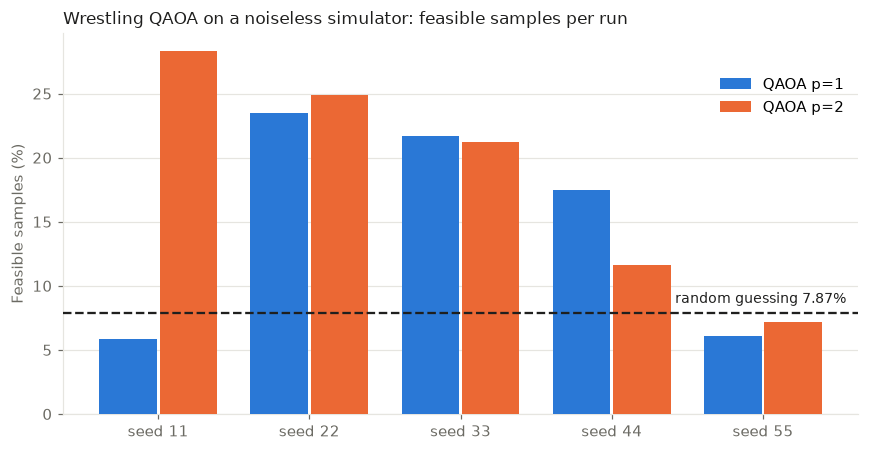

In [12]:
# Chart: feasible-sample rate per seed vs. random guessing (from the saved sweep)
seeds = sorted({t["seed"] for t in sweep["trials"]})
feas = {d: [next(t["feasible_percent"] for t in sweep["trials"] if t["depth"] == d and t["seed"] == s)
            for s in seeds] for d in (1, 2)}
INK, MUTED, GRID = "#1f1f1e", "#6b6a63", "#e6e5e0"
SERIES = {1: "#2a78d6", 2: "#eb6834"}   # validated categorical slots 1-2

fig, ax = plt.subplots(figsize=(8, 4.2), dpi=110)
x = np.arange(len(seeds)); w = 0.38
for i, d in enumerate((1, 2)):
    ax.bar(x + (i - 0.5) * w * 1.05, feas[d], width=w, color=SERIES[d], label=f"QAOA p={d}", zorder=3)
ax.axhline(100 * 1289 / 16384, color=INK, linestyle="--", linewidth=1.5, zorder=4)
ax.text(len(seeds) - 0.45, 100 * 1289 / 16384 + 0.8, "random guessing 7.87%", ha="right", color=INK, fontsize=9)
ax.set_xticks(x, [f"seed {s}" for s in seeds])
ax.set_ylabel("Feasible samples (%)", color=MUTED)
ax.set_title("Wrestling QAOA on a noiseless simulator: feasible samples per run", loc="left", fontsize=11, color=INK)
ax.grid(axis="y", color=GRID, zorder=0); ax.set_axisbelow(True)
for sp in ("top", "right"): ax.spines[sp].set_visible(False)
for sp in ("left", "bottom"): ax.spines[sp].set_color(GRID)
ax.tick_params(colors=MUTED)
ax.legend(frameon=False, loc="upper right", bbox_to_anchor=(1, 0.92))
plt.tight_layout(); plt.show()

### 6c. Live check: re-sampling one saved QAOA result

To show the pipeline working live, we take the **saved optimized angles** from the
best p=1 run (seed 22) and do two things. Neither one changes any saved file:

* compute the **exact** probabilities from the quantum state, with no shot noise, and
* draw a **fresh** 4,000-shot sample on the Aer simulator.

The two numbers will differ slightly from each other, and from the saved 23.48%,
because of random sampling. This is a re-check, not a new experiment.

In [13]:
# Live check: exact and re-sampled results for the saved p=1, seed 22 angles
from qiskit.quantum_info import Statevector
from qiskit_aer.primitives import SamplerV2

best = next(t for t in sweep["trials"] if t["depth"] == 1 and t["seed"] == 22)
circ, op, offset, scale = build_circuit(inst, 1)
names = [p.name for p in circ.parameters]          # sorted: beta, gamma
angles = dict(zip(names, best["optimal_parameters"]))
print("Saved angles:", {k: round(v, 4) for k, v in angles.items()})

# Exact probabilities (statevector, index = assignment integer, qubit i = bit i)
exact_circ = qaoa_ansatz(cost_operator=op / scale, reps=1)
probs = Statevector(exact_circ.assign_parameters({p: angles[p.name] for p in exact_circ.parameters})).probabilities()
feasible_mask = np.array([is_feasible(x, inst) for x in range(2**14)])
optimal_x = ver["ground_states"][0]
print(f"Exact feasible probability:  {100*probs[feasible_mask].sum():.2f}%")
print(f"Exact optimal probability:   {100*probs[optimal_x]:.4f}%  (random: {100/16384:.4f}%)")

# Fresh 4,000-shot simulator sample
bound = circ.assign_parameters({p: angles[p.name] for p in circ.parameters})
counts = SamplerV2(seed=2026).run([bound], shots=4000).result()[0].data.meas.get_counts()
feas_shots = sum(c for b, c in counts.items() if is_feasible(bitstring_to_selection(b), inst))
opt_shots = counts.get(format(optimal_x, "014b"), 0)
print(f"Fresh sample feasible:       {100*feas_shots/4000:.2f}%  ({feas_shots}/4000)")
print(f"Fresh sample optimal hits:   {opt_shots}")
print(f"Saved run (for reference):   {best['feasible_percent']:.2f}% feasible, {best['optimal_shots']} optimal hits")

Saved angles: {'β[0]': -0.2523, 'γ[0]': 0.1921}
Exact feasible probability:  23.58%
Exact optimal probability:   0.0169%  (random: 0.0061%)
Fresh sample feasible:       23.25%  (930/4000)
Fresh sample optimal hits:   1
Saved run (for reference):   23.48% feasible, 2 optimal hits


## 7. Comparing classical and quantum approaches

All numbers below come from saved result files.

In [14]:
# Saved results: wrestling 14-variable decision, five seeds per depth
cref = sweep["classical_reference"]
s1, s2 = sweep["summaries"]
print("WRESTLING MAT SELECTION (14 variables)")
print(f"{'Method':<28} {'Feasible':>14} {'Found optimum':>15} {'Typical time':>14}")
print(f"{'Classical greedy':<28} {'100% (always)':>14} {'every run':>15} {'~10 µs':>14}")
print(f"{'Classical brute force':<28} {'100% (always)':>14} {'every run':>15} {'~3 ms':>14}")
print(f"{'QAOA p=1 (simulator)':<28} {s1['feasible_percent']['mean']:>13.2f}% {str(s1['runs_finding_optimum'])+'/5 runs':>15} {s1['runtime_s']['mean']:>12.2f} s")
print(f"{'QAOA p=2 (simulator)':<28} {s2['feasible_percent']['mean']:>13.2f}% {str(s2['runs_finding_optimum'])+'/5 runs':>15} {s2['runtime_s']['mean']:>12.2f} s")
print(f"{'Random guessing':<28} {7.867:>13.2f}% {'21.7% per run':>15} {'-':>14}")
print("\nclassical_reference stored in sweep file:", json.dumps(cref)[:300])

WRESTLING MAT SELECTION (14 variables)
Method                             Feasible   Found optimum   Typical time
Classical greedy              100% (always)       every run         ~10 µs
Classical brute force         100% (always)       every run          ~3 ms
QAOA p=1 (simulator)                 14.93%        3/5 runs         1.38 s
QAOA p=2 (simulator)                 18.66%        2/5 runs         2.80 s
Random guessing                       7.87%   21.7% per run              -

classical_reference stored in sweep file: {"repeats": 20, "brute_force_score": 12, "brute_force_n_optimal": 1, "brute_force_median_time_s": 0.003120399996987544, "greedy_score": 12, "greedy_median_time_s": 9.849994967225939e-06}


In [15]:
# Saved results: 4-team round-robin league (18 variables) - QAOA vs classical
bench = load("benchmark_results.json")
sa = load("sa_benchmark_results.json")["sa_summary"]
cb = bench["classical_baseline"]
print("4-TEAM ROUND-ROBIN (18 variables)")
print(f"{'Method':<28} {'Successful runs':>16} {'Median time':>14}")
print(f"{'Classical backtracking':<28} {str(cb['repeats'])+'/'+str(cb['repeats']):>16} {cb['median_time_s']*1e6:>11.1f} µs")
print(f"{'Simulated annealing':<28} {str(sa['successful_runs'])+'/'+str(sa['n_runs']):>16} {sa['median_time_s']*1e3:>11.1f} ms")
for s in bench["summaries"]:
    print(f"{'QAOA p='+str(s['depth'])+' (simulator)':<28} {str(s['successful_trials'])+'/'+str(s['n_trials']):>16} {s['median_total_time_s']:>12.2f} s")

4-TEAM ROUND-ROBIN (18 variables)
Method                        Successful runs    Median time
Classical backtracking                200/200         9.5 µs
Simulated annealing                     30/30        11.5 ms
QAOA p=1 (simulator)                      1/5         2.06 s
QAOA p=2 (simulator)                      3/5         4.76 s
QAOA p=3 (simulator)                      4/5         6.95 s


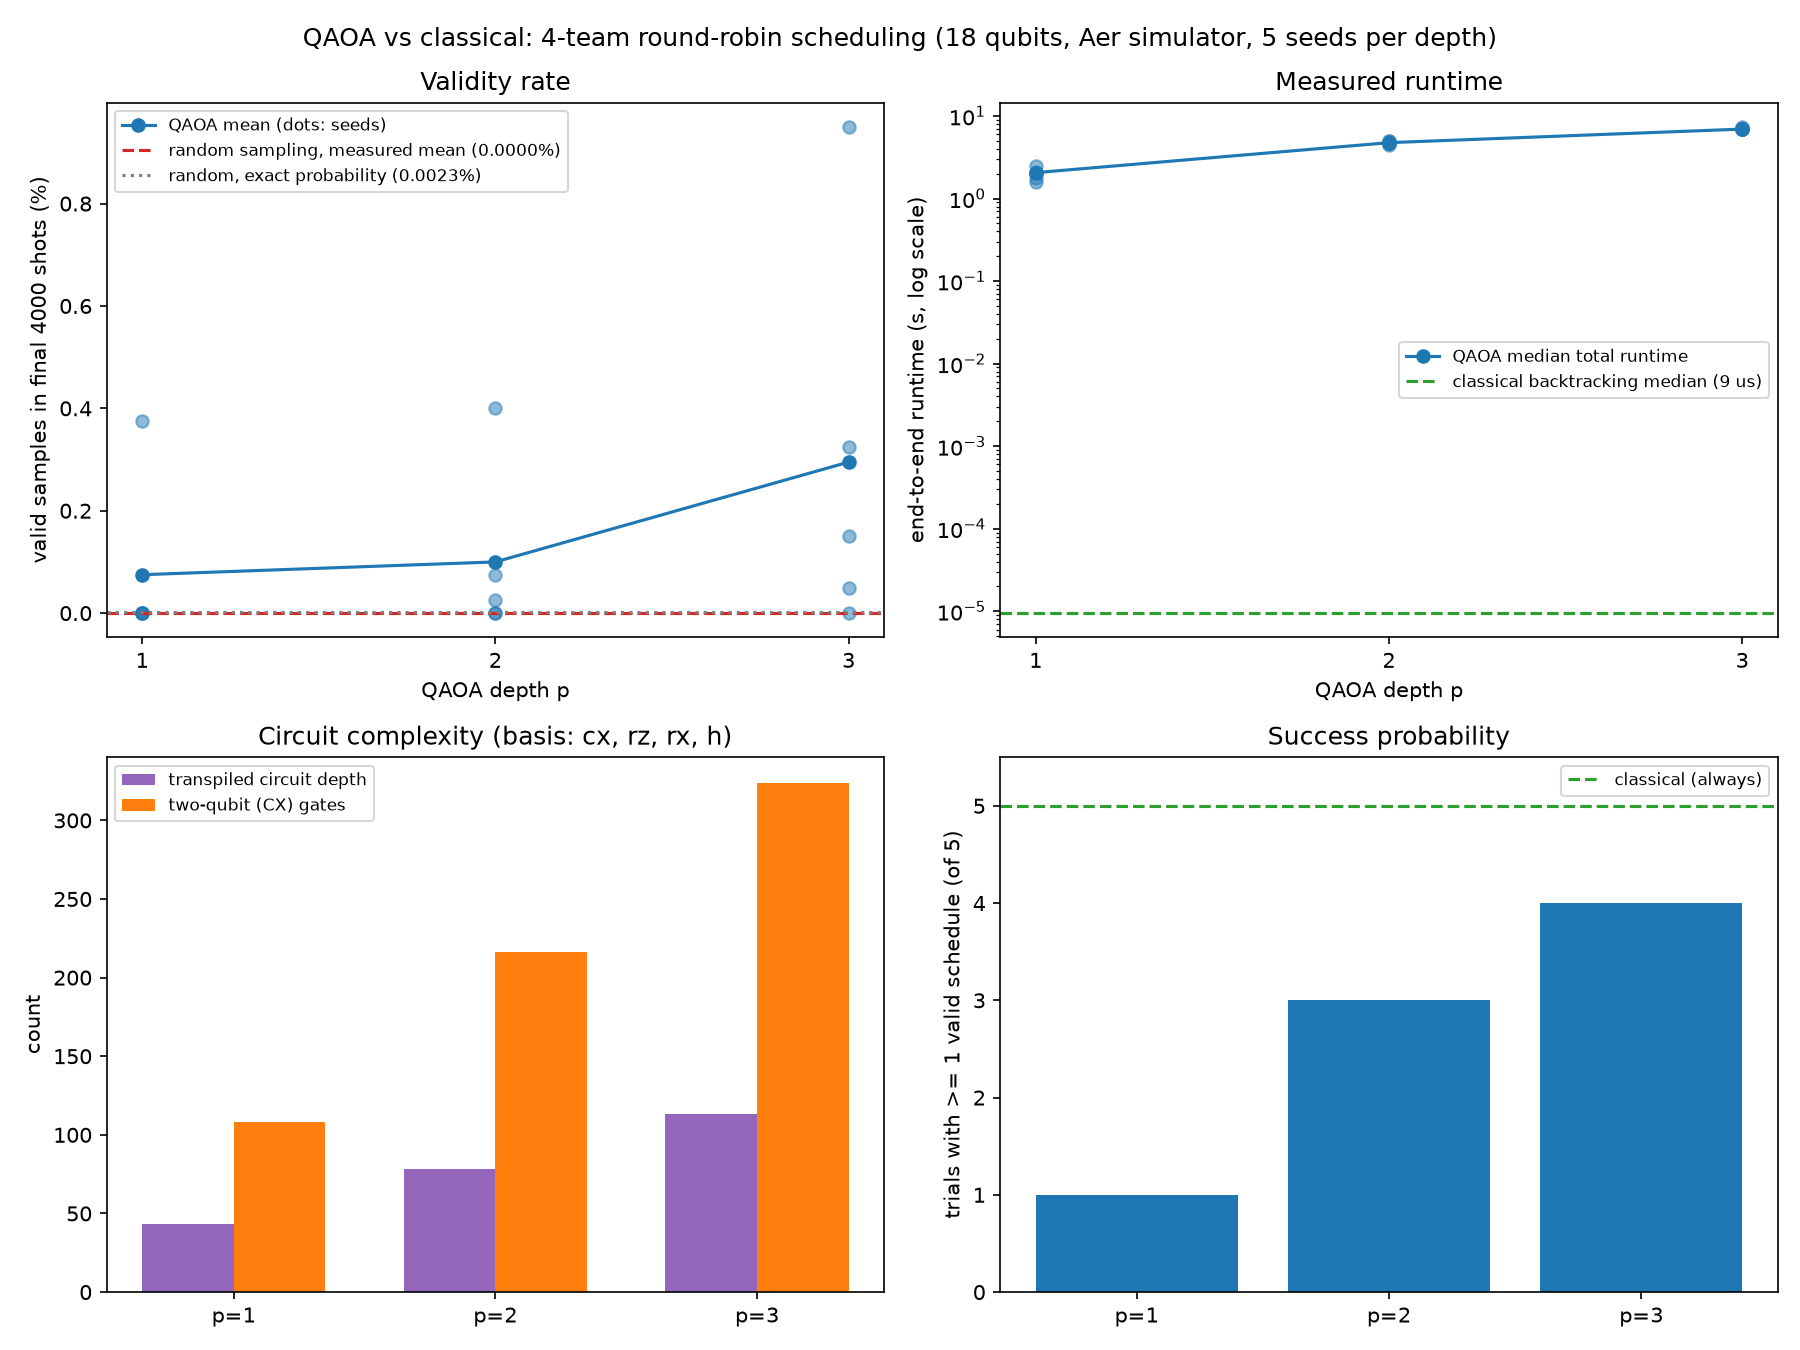

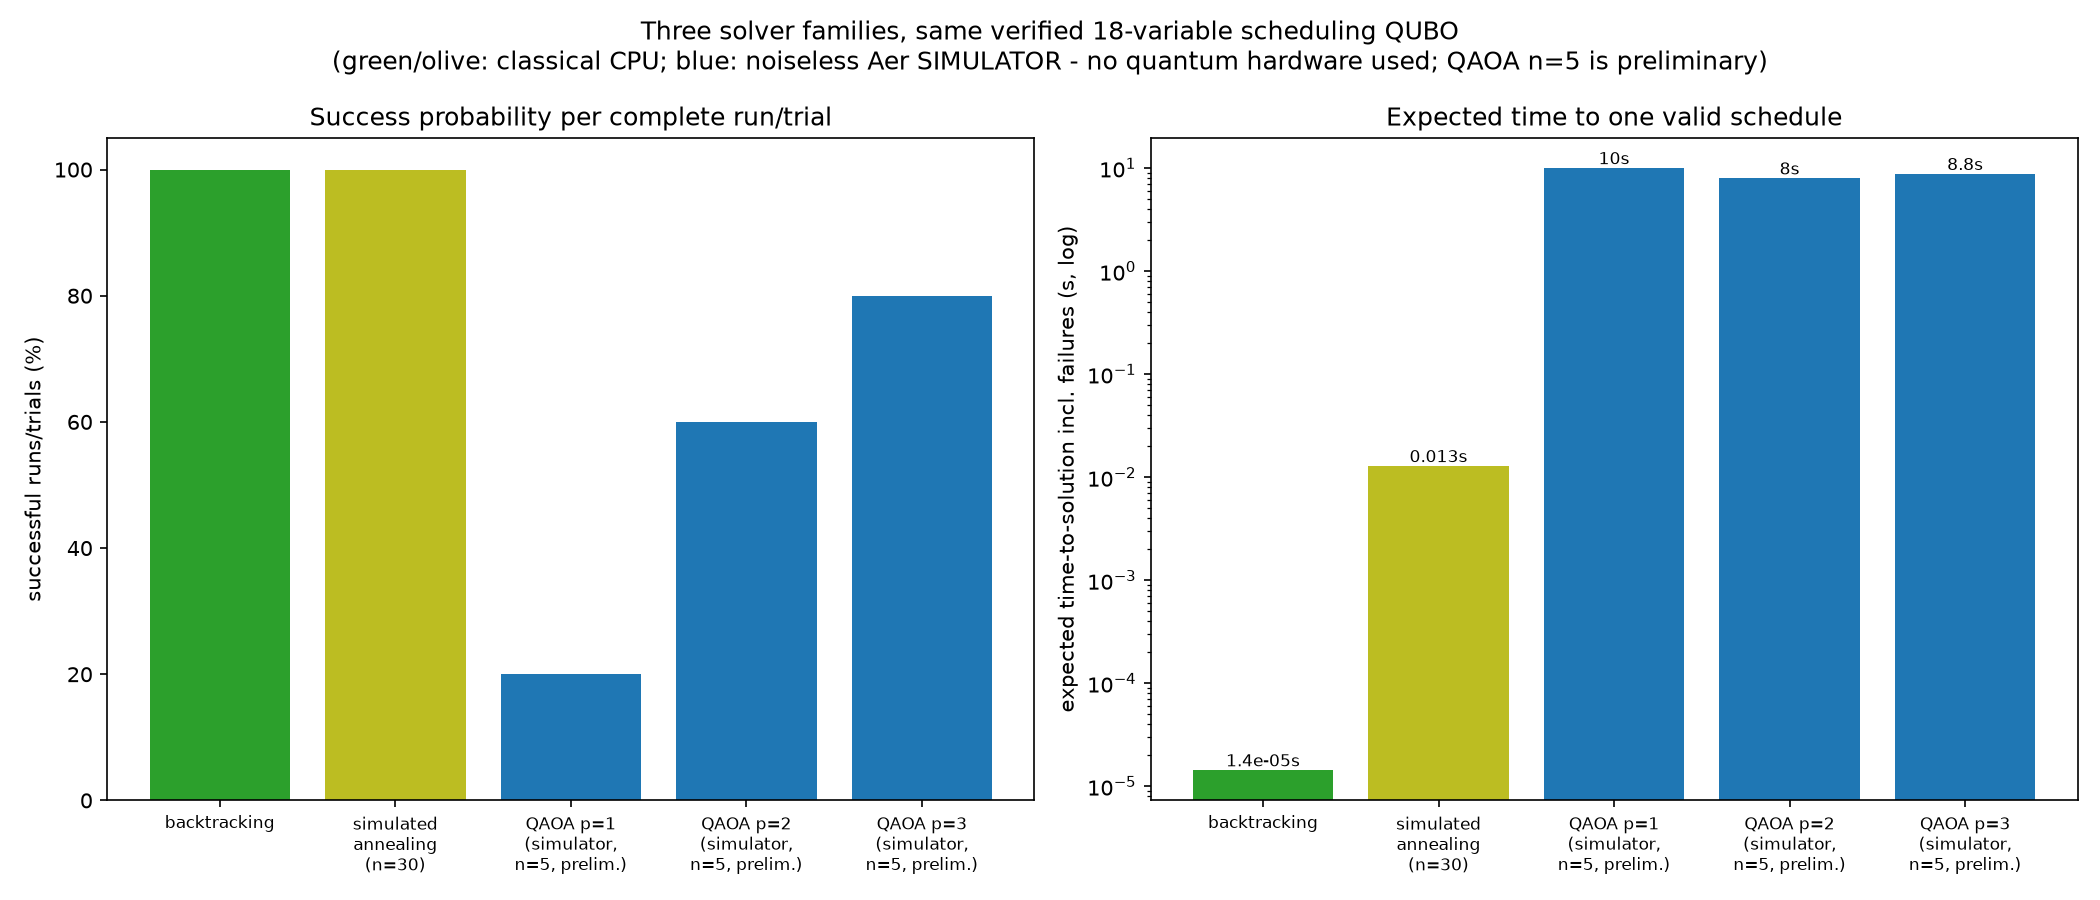

In [16]:
# Saved charts from the round-robin study
display(Image(filename=str(RESULTS / "benchmark_charts.png"), width=850))
display(Image(filename=str(RESULTS / "solver_comparison_charts.png"), width=850))

**What the comparison shows**

* QAOA produced **more feasible answers than random guessing on average**
  (14.9% and 18.7% vs. 7.9%). The results varied a lot from seed to seed: some runs
  were close to random (about 6%) and some were around 23–28%.
* **p=2 was not consistently better than p=1.** The difference was not statistically
  significant (Mann-Whitney p = 0.42).
* **Classical greedy found the optimum every time in about 10 µs.** QAOA took
  1–3 seconds per run on the simulator and found the optimum in only some runs.
* Simulator runtimes are **not** quantum hardware runtimes. They show what it costs to
  imitate a quantum computer on a laptop.

## 8. Did the quantum algorithm produce valid schedules?

**Yes, sometimes.** For every QAOA run we took each distinct feasible answer,
completed the full tournament schedule from it, and checked it with the
**independent validator**.

In [17]:
# Saved result: validator results across all ten sweep runs
checked = sum(t["validation"]["distinct_feasible_checked"] for t in sweep["trials"])
failed = sum(t["validation"]["validator_failures"] for t in sweep["trials"])
print(f"Feasible QAOA answers checked (distinct per run, summed over 10 runs): {checked}")
print(f"Validator failures:                                                {failed}")

Feasible QAOA answers checked (distinct per run, summed over 10 runs): 4958
Validator failures:                                                0


In [18]:
# Live check: decode the most frequent feasible answer from the fresh sample above and validate it
feasible_counts = {bitstring_to_selection(b): c for b, c in counts.items()
                   if is_feasible(bitstring_to_selection(b), inst)}
x_top = max(feasible_counts, key=feasible_counts.get)
chosen = [inst["pool"][i] for i in range(14) if (x_top >> i) & 1]
print(f"Most frequent feasible answer ({feasible_counts[x_top]} of 4000 shots):")
for mat, mid in enumerate(chosen, 1):
    print(f"  Mat {mat}: {mid}")
print(f"Score: {selection_score(x_top, inst)} (optimum is {ver['optimal_score']})")
print("Full tournament from this choice passes the independent validator:",
      validator_agreement(snapshot, x_top))

Most frequent feasible answer (5 of 4000 shots):
  Mat 1: W106-R4-S1
  Mat 2: W113-R4-S1
  Mat 3: W160-R3-S1
  Mat 4: W182-R3-S2
  Mat 5: W220-R3-S1
  Mat 6: W285-R3-S2
Score: 9 (optimum is 12)
Full tournament from this choice passes the independent validator: True


## 9. Real IBM quantum hardware

> **Please read.** Our team ran **two** jobs on real IBM quantum hardware (`ibm_fez`):
> 1. a **2-qubit Bell-state test** (Nov 9), which only checks our hardware workflow and
>    is **not** our scheduling algorithm, and
> 2. **our 14-qubit wrestling scheduling QAOA** (Nov 10, section 9c).
>
> All QAOA results in sections 5–8 come from the noiseless **simulator**.

### 9a. Bell-state test on ibm_fez. Saved result, real hardware.

In [19]:
# Saved result: parse the recorded Bell-state hardware report (job dbovmec4148s739tmr50)
import re
report = (RESULTS / "bell_state_ibm_fez_2026-11-09.md").read_text(encoding="utf-8-sig")

def section_counts(title):
    block = report.split(f"## {title}")[1].split("##")[0]
    return {k: int(v) for k, v in re.findall(r"^([01]{2}): (\d+)", block, flags=re.M)}

for key in ("Date", "Processor", "Job ID", "Job status", "Hardware shots"):
    print(f"{key + ':':<16}", re.search(rf"^{key}: (.+)$", report, flags=re.M).group(1))
sim, hw = section_counts("Simulator Results"), section_counts("Real IBM Hardware Results")
print(f"\n{'outcome':>8} {'simulator':>10} {'ibm_fez':>8}")
for o in ("00", "01", "10", "11"):
    print(f"{o:>8} {sim[o]:>10} {hw[o]:>8}")
hw_total = sum(hw.values())
print(f"\nHardware correlated outcomes (00 or 11): {hw['00']+hw['11']}/{hw_total} = {100*(hw['00']+hw['11'])/hw_total:.0f}%")
print("Ideal Bell state: only 00 and 11. The 5 '01' results show real hardware noise.")

Date:            November 9, 2026
Processor:       ibm_fez
Job ID:          dbovmec4148s739tmr50
Job status:      DONE
Hardware shots:  100

 outcome  simulator  ibm_fez
      00        498       49
      01          0        5
      10          0        0
      11        502       46

Hardware correlated outcomes (00 or 11): 95/100 = 95%
Ideal Bell state: only 00 and 11. The 5 '01' results show real hardware noise.


### 9b. Is our scheduling circuit ready for hardware? Live local check, no hardware used

A real processor only connects certain qubits and only runs certain gates, so the
circuit has to be **transpiled** (rewritten) for it. Below, we transpile our p=1
wrestling QAOA circuit for `FakeFez`, a **local snapshot** of the ibm_fez chip. This
runs entirely on this computer and uses no QPU time.

In [20]:
# Live local check: transpile the p=1 QAOA for a local snapshot of ibm_fez
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit_ibm_runtime.fake_provider import FakeFez

backend = FakeFez()
logical = qaoa_ansatz(cost_operator=op / scale, reps=1)
logical.measure_all()
for level in (1, 2, 3):
    isa = generate_preset_pass_manager(optimization_level=level, backend=backend,
                                       seed_transpiler=1234).run(logical)
    ops = isa.count_ops()
    print(f"Optimization level {level}: depth {isa.depth():>4}, two-qubit (CZ) gates {ops.get('cz', 0):>4}")
print(f"\nBackend snapshot: {backend.name}, {backend.num_qubits} qubits")
print("Compare: the logical p=1 circuit had depth 79 and 182 CX gates.")

Optimization level 1: depth  593, two-qubit (CZ) gates  422
Optimization level 2: depth  485, two-qubit (CZ) gates  365
Optimization level 3: depth  462, two-qubit (CZ) gates  334

Backend snapshot: fake_fez, 156 qubits
Compare: the logical p=1 circuit had depth 79 and 182 CX gates.


**Note on these numbers:** the transpiler uses randomness when it places and routes
qubits, so gate counts change from run to run. The counts above come from this
notebook run (seed 1234). Our saved report from November 9 recorded a different run:
depth 442 and 320 CZ gates at Level 2, and 440 / 330 at Level 3. That run didn't
record its random seed, so we can't reproduce its exact numbers. Either way, the
hardware circuit needs **roughly 320–420 two-qubit gates**.

The hardware version of the circuit is **much longer** than the logical one, because
the chip only connects neighbouring qubits. Each two-qubit gate on real hardware
carries a small error, and with hundreds of them **we expect noise to strongly
affect the results**. Our separate saved report
(`results/qaoa_hardware_optimization_validation_2026-11-09.md`) also confirmed that
the optimized hardware circuit gives the same ideal probabilities as the original
for four test settings.

### 9c. Scheduling QAOA on real IBM hardware (ibm_fez). Saved result, real hardware

We ran **our actual 14-qubit wrestling QAOA circuit** on IBM's `ibm_fez` processor
as **one job of 4,000 shots**. We reused the **saved p=1 angles from simulator seed
22**, so there was no optimization on the hardware. The script is
`hardware/qaoa_hardware.py`. It transpiles the circuit for the chip, checks that the
compiled circuit gives the same ideal probabilities, submits the job, and scores every
sample with our original rules and independent validator.

The cell below **reads the saved hardware result file**. It also reads the local noise
prediction we made *before* the run, which uses FakeFez, a model of the chip and
**not** a measurement.

In [21]:
# Saved result: real hardware run of the scheduling QAOA + the pre-run prediction
hw_files = sorted((RESULTS / "hardware").glob("hardware_result_ibm_fez_*.json"))
pre_files = sorted((RESULTS / "hardware").glob("preflight_fakefez_*.json"))
assert len(hw_files) == 1, f"expected exactly one hardware result file, found {len(hw_files)}"
hwrec = json.loads(hw_files[0].read_text(encoding="utf-8"))
pre = json.loads(pre_files[0].read_text(encoding="utf-8"))
job, comp, H = hwrec["job"], hwrec["compatibility"], hwrec["hardware"]

print(f"Job ID:         {job['job_id']}")
print(f"Processor:      {job['backend']}   status: {job['status']}")
print(f"Shots:          {H['shots']}")
print(f"QPU usage reported by IBM: {job.get('usage_seconds_reported_by_ibm')} s")
print(f"Circuit on chip: {comp['physical_qubits_used']} qubits, depth {comp['isa_depth']}, "
      f"{comp['isa_two_qubit_gates']} two-qubit gates")
print(f"Compiled circuit equals our simulator circuit (ideal): "
      f"{hwrec['equivalence_check']['passes_1e-6']}")

Job ID:         dbppooc4148s739v0lsg
Processor:      ibm_fez   status: DONE
Shots:          4000
QPU usage reported by IBM: 0 s
Circuit on chip: 14 qubits, depth 356, 280 two-qubit gates
Compiled circuit equals our simulator circuit (ideal): True


In [22]:
# Comparison table: measurement vs. prediction vs. baselines
ex = hwrec["exact_noiseless_for_saved_parameters"]
sv = hwrec["saved_simulator_parameters"]
NP = pre["noisy_prediction"]
rows = [
    ("Perfect quantum computer (exact math)", "calculation", ex["feasible_percent"], None, ex["mean_qubo_energy"]),
    ("Saved simulator run, 4,000 shots",       "simulator",   sv["simulator_feasible_percent"], sv["simulator_optimal_shots"], None),
    ("FakeFez noise model, 4,000 shots",       "PREDICTION",  NP["feasible_percent"], NP["optimal_shots"], NP["mean_qubo_energy"]),
    ("ibm_fez REAL HARDWARE, 4,000 shots",     "MEASURED",    H["feasible_percent"], H["optimal_shots"], H["mean_qubo_energy"]),
    ("Random guessing (exact)",                "calculation", 100 * 1289 / 16384, None, 61.5),
]
print(f"{'Source':<40} {'type':<12} {'feasible %':>10} {'optimal hits':>13} {'mean energy':>12}")
for name, kind, f, o, e in rows:
    print(f"{name:<40} {kind:<12} {f:>10.2f} {('-' if o is None else o):>13} {('-' if e is None else f'{e:.1f}'):>12}")
lo, hi = H["feasible_percent_ci95_clopper_pearson"]
print(f"\nHardware feasible rate 95% confidence interval: {lo:.1f}% to {hi:.1f}%")
print(f"Chance of doing this well by random guessing (one-sided binomial p-value): "
      f"{H['p_value_feasible_greater_than_random']:.2g}")
v = H["validation"]
print(f"Independent validator: {v['distinct_feasible_checked']} distinct feasible hardware answers checked, "
      f"{v['validator_failures']} failures")
print(f"Best feasible score found on hardware: {H['best_feasible_score']} (optimum is 12)")

Source                                   type         feasible %  optimal hits  mean energy
Perfect quantum computer (exact math)    calculation       23.58             -          8.9
Saved simulator run, 4,000 shots         simulator         23.48             2            -
FakeFez noise model, 4,000 shots         PREDICTION        17.43             1         15.8
ibm_fez REAL HARDWARE, 4,000 shots       MEASURED          13.20             0         29.7
Random guessing (exact)                  calculation        7.87             -         61.5

Hardware feasible rate 95% confidence interval: 12.2% to 14.3%
Chance of doing this well by random guessing (one-sided binomial p-value): 7.3e-31
Independent validator: 423 distinct feasible hardware answers checked, 0 failures
Best feasible score found on hardware: 11 (optimum is 12)


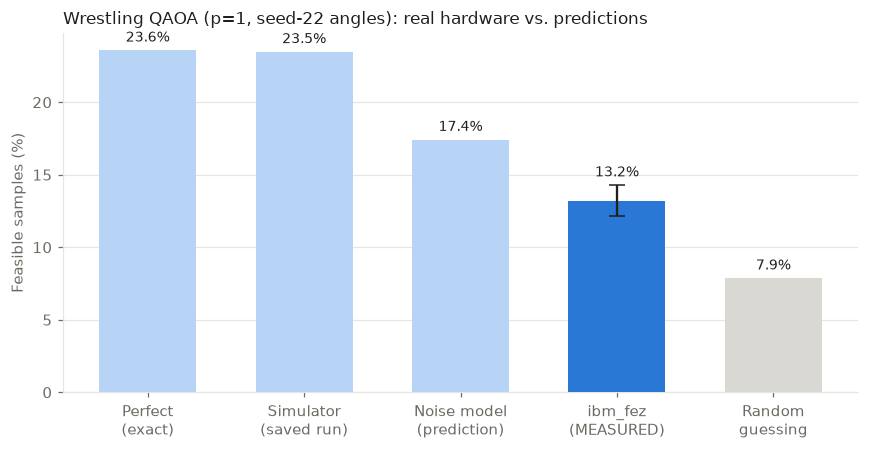

Error bar = 95% confidence interval for the hardware measurement.


In [23]:
# Chart: feasible-sample rate by source (hardware measurement highlighted)
labels = ["Perfect\n(exact)", "Simulator\n(saved run)", "Noise model\n(prediction)", "ibm_fez\n(MEASURED)", "Random\nguessing"]
vals = [ex["feasible_percent"], sv["simulator_feasible_percent"], NP["feasible_percent"],
        H["feasible_percent"], 100 * 1289 / 16384]
colors = ["#b7d3f6", "#b7d3f6", "#b7d3f6", "#2a78d6", "#d9d8d2"]
fig, ax = plt.subplots(figsize=(8, 4.2), dpi=110)
bars = ax.bar(labels, vals, color=colors, width=0.62, zorder=3)
ax.errorbar(3, H["feasible_percent"], yerr=[[H["feasible_percent"] - lo], [hi - H["feasible_percent"]]],
            color=INK, capsize=5, linewidth=1.5, zorder=4)
for i, (b, v_) in enumerate(zip(bars, vals)):
    top = hi if i == 3 else v_          # keep the hardware label clear of its error bar
    ax.text(b.get_x() + b.get_width() / 2, top + 0.6, f"{v_:.1f}%", ha="center", color=INK, fontsize=9)
ax.set_ylabel("Feasible samples (%)", color=MUTED)
ax.set_title("Wrestling QAOA (p=1, seed-22 angles): real hardware vs. predictions", loc="left", fontsize=11, color=INK)
ax.grid(axis="y", color=GRID, zorder=0); ax.set_axisbelow(True)
for sp in ("top", "right"): ax.spines[sp].set_visible(False)
for sp in ("left", "bottom"): ax.spines[sp].set_color(GRID)
ax.tick_params(colors=MUTED)
plt.tight_layout(); plt.show()
print("Error bar = 95% confidence interval for the hardware measurement.")

In [24]:
# Live check: re-validate the most frequent feasible hardware answer from the saved counts
hc = hwrec["hardware_counts"]
feas_hw = {bitstring_to_selection(b): c for b, c in hc.items() if is_feasible(bitstring_to_selection(b), inst)}
x_hw = max(feas_hw, key=feas_hw.get)
print(f"Most frequent feasible answer on ibm_fez ({feas_hw[x_hw]} of {sum(hc.values())} shots):")
for mat, i in enumerate([i for i in range(14) if (x_hw >> i) & 1], 1):
    print(f"  Mat {mat}: {inst['pool'][i]}")
print(f"Score: {selection_score(x_hw, inst)} (optimum is 12)")
print("Full tournament from this hardware answer passes the independent validator:",
      validator_agreement(snapshot, x_hw))

Most frequent feasible answer on ibm_fez (4 of 4000 shots):
  Mat 1: W106-R4-S1
  Mat 2: W152-R3-S1
  Mat 3: W182-R3-S1
  Mat 4: W195-R3-S1
  Mat 5: W220-R3-S2
  Mat 6: W285-R3-S1
Score: 8 (optimum is 12)
Full tournament from this hardware answer passes the independent validator: True


**What the hardware result means (measured, job `dbppooc4148s739v0lsg`)**

* **The real chip did better than random guessing.** 13.2% of the 4,000 hardware samples
  were feasible schedules, vs. 7.9% for random guessing. That's about 1.7 times as
  many, and very unlikely to be luck (p ≈ 7×10⁻³¹). The hardware samples also had a
  much lower average energy than random (29.7 vs. 61.5). Every feasible hardware answer
  passed the independent validator.
* **Noise cost a lot.** A perfect quantum computer would give 23.6% feasible, and our
  simulator gave 23.5%. On the real chip we got 13.2%, which is about 44% lower. The
  compiled circuit has 280 two-qubit gates, and each one adds a little error.
* **The real chip was noisier than our model predicted.** The FakeFez noise model
  predicted 17.4% (a prediction, made before the run). The measured 13.2% is clearly
  lower (p ≈ 2×10⁻⁷), so the model left out some real noise sources.
* **The single best answer (score 12) did not appear.** This is expected: even a perfect
  machine would give it only about 0.7 times in 4,000 shots. The best hardware answer
  scored 11.
* **Classical greedy still wins:** it finds the optimum every time in about 10 µs. This
  hardware run shows our scheduling algorithm *works* on a real quantum computer. It
  does **not** show a quantum advantage.

## 10. Conclusions and limitations

**What worked**
* A classical greedy scheduler built a **valid, optimal 118-match schedule**
  (20 slots = lower bound), checked by an independent validator.
* We turned a real scheduling decision into a **QUBO** and **checked it against all
  16,384 answers** before running quantum code.
* **QAOA on a simulator produced valid schedules**, more often than random guessing
  on average. Every feasible answer passed the validator.
* We ran **our scheduling QAOA on a real IBM quantum processor** (ibm_fez, 4,000 shots,
  280 two-qubit gates). **13.2% of hardware samples were valid schedules vs. 7.9% for
  random guessing**, and all of them passed the validator. A Bell-state test (95/100
  correlated outcomes) confirmed our hardware workflow first.

**What we cannot claim**
* **No quantum advantage.** Classical code was faster and more reliable on every
  problem we tested.
* p=2 was not reliably better than p=1. Results depended strongly on the random seed.
* Real hardware noise **cut the valid-schedule rate from 23.5% (simulator) to 13.2%**,
  below even our noise-model prediction (17.4%). The hardware result is **one job with
  one set of angles**, and the best answer (score 12) never appeared on hardware.
* The tournament is fictional and simplified, and the 14-variable instance is easy
  for greedy.
* Five seeds per depth is a small sample.

**Future work**
* Harder scheduling instances where simple greedy methods are not already optimal.
* More seeds, larger optimizer budgets, and better QAOA objectives (e.g. CVaR).
* Repeat the hardware run (more jobs, other angles), and try error-mitigation options
  and shorter circuits to reduce the effect of noise.

**Our main lesson:** check the answer, not the algorithm. A strong classical
baseline and an independent validator kept our quantum results honest.

In [25]:
# Final integrity check: no saved result file was created, changed or deleted by this notebook
AFTER = fingerprint()
assert AFTER == BEFORE, "A saved result changed!"
print(f"OK: all {len(AFTER)} saved result files are unchanged.")

OK: all 17 saved result files are unchanged.
